In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest

In [3]:
import sqlite3
db_path = r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db"
conn = sqlite3.connect(db_path)

# Check available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table';
    """,
    conn
)

print("Available tables:")
display(tables)

Available tables:


,name
0,crop_recommendation
1,agri_yield_train
2,agri_yield_test
3,crop_recommendation_clean
4,agri_yield_train_clean
5,agri_yield_test_clean
6,crop_recommendation_fe
7,agri_yield_train_fe
8,agri_yield_test_fe
9,crop_recommendation_selected


In [4]:
sf24 = pd.read_sql_query(
    "SELECT * FROM crop_recommendation_selected",
    conn
)


In [5]:
X = sf24.drop(columns=["label"])

print("Number of records:", X.shape[0])
print("Number of features:", X.shape[1])
print("Feature columns:", X.columns.tolist())

Number of records: 2200
Number of features: 12
Feature columns: ['humidity', 'K', 'temperature', 'N', 'P_K_Ratio', 'NPK_Total', 'Temperature_Rainfall', 'rainfall', 'N_K_Ratio', 'Humidity_Rainfall', 'Temperature_Humidity', 'P']


In [6]:
print("Missing values:", X.isnull().sum().sum())
print("Duplicate feature rows:", X.duplicated().sum())
print("Non-numeric columns:", X.select_dtypes(exclude=np.number).columns.tolist())

Missing values: 0
Duplicate feature rows: 0
Non-numeric columns: []


In [7]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Scaled data shape:", X_scaled.shape)

Scaled data shape: (2200, 12)


In [8]:
model = IsolationForest(
    contamination=0.05,
    random_state=42
)

predictions = model.fit_predict(X_scaled)

sf24_anomalies = sf24.copy()
sf24_anomalies["anomaly"] = predictions

sf24_anomalies["anomaly"] = sf24_anomalies["anomaly"].map({
    1: "Normal",
    -1: "Anomaly"
})

print(sf24_anomalies["anomaly"].value_counts())

anomaly
Normal     2090
Anomaly     110
Name: count, dtype: int64


In [9]:
counts = sf24_anomalies["anomaly"].value_counts()

percentages = sf24_anomalies["anomaly"].value_counts(normalize=True) * 100

print("Record counts:")
print(counts)

print("\nPercentages:")
print(percentages.round(2))

Record counts:
anomaly
Normal     2090
Anomaly     110
Name: count, dtype: int64

Percentages:
anomaly
Normal     95.0
Anomaly     5.0
Name: proportion, dtype: float64


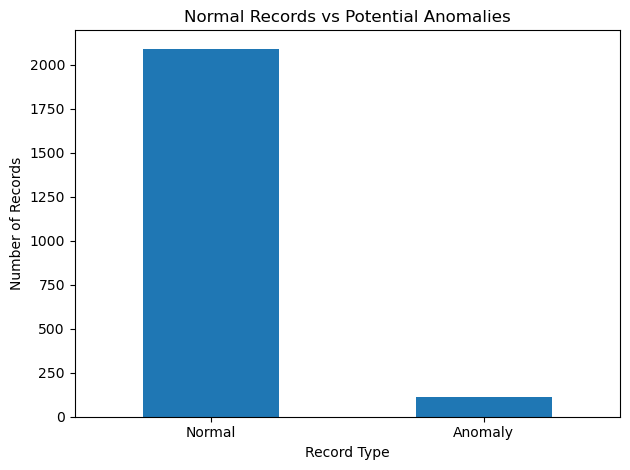

In [10]:
sf24_anomalies["anomaly"].value_counts().plot(
    kind="bar",
    title="Normal Records vs Potential Anomalies"
)

plt.xlabel("Record Type")
plt.ylabel("Number of Records")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [11]:
anomalies = sf24_anomalies[
    sf24_anomalies["anomaly"] == "Anomaly"
]

display(anomalies.head(10))

,humidity,K,temperature,N,P_K_Ratio,NPK_Total,Temperature_Rainfall,rainfall,N_K_Ratio,Humidity_Rainfall,Temperature_Humidity,P,label,anomaly
12,80.886848,44,26.800796,78,1.318182,180,7623.123462,284.436457,1.772727,23007.168501,2167.831921,58,rice,Anomaly
19,83.587603,40,23.579436,88,0.875000,163,6868.658229,291.298662,2.200000,24348.956944,1970.948561,35,rice,Anomaly
26,84.044036,43,26.359272,97,1.372093,199,7152.815397,271.358614,2.255814,22806.073069,2215.339568,59,rice,Anomaly
36,81.177340,35,26.757542,99,1.628571,191,7286.076082,272.299906,2.828571,22104.582049,2172.106064,57,rice,Anomaly
37,83.152508,36,23.863305,95,1.083333,170,6806.992492,285.249365,2.638889,23719.200066,1984.293633,39,rice,Anomaly
38,82.952217,44,21.019447,60,0.977273,147,6272.241798,298.401847,1.363636,24753.094851,1743.609731,43,rice,Anomaly
43,84.813601,40,23.830675,82,1.000000,162,7114.889116,298.560117,2.050000,25321.958761,2021.165364,40,rice,Anomaly
54,83.836258,36,26.229169,95,1.444444,183,7514.876514,286.508373,2.638889,24019.789891,2198.955382,52,rice,Anomaly
62,83.773456,38,20.615214,93,1.526316,189,5762.883604,279.545172,2.447368,23418.465027,1727.007735,58,rice,Anomaly
72,82.840226,37,24.873007,79,1.135135,158,7352.696029,295.609449,2.135135,24488.353435,2060.485545,42,rice,Anomaly


In [12]:
import os

os.makedirs("stage9_outputs", exist_ok=True)

sf24_anomalies.to_csv(
    "stage9_outputs/sf24_anomaly_results.csv",
    index=False
)

print("Saved: stage9_outputs/sf24_anomaly_results.csv")

Saved: stage9_outputs/sf24_anomaly_results.csv
